# Lab5: Lastflyt i et enkelt kraftsystem

## Læringsmål

Etter gjennomført lab skal du kunne:

- Modellere et kraftsystem ved hjelp av impedanser og Y-bussmatrise.
- Utføre lastflytberegninger i et 2-bussystem.
- Utvide modellen til et 3-bussystem.
- Sammenligne teoretiske beregninger med numeriske resultater.
- Analysere spenningsnivåer og effektflyt i nettet.

---

# Del 1: 2-bussystem

## Systembeskrivelse

Vi betrakter et enkelt distribusjonssystem bestående av:

- Buss 1: Slack-buss
- Buss 2: Lastbuss (PQ-buss)

Data:

$$
V_1 = 1.00 \angle 0^\circ \ \text{p.u.}
$$

Linjeimpedans:

$$
Z_{12}=0.02+j0.08 \ \text{p.u.}
$$

Last på buss 2:

$$
S_2 = 0.80 + j0.30 \ \text{p.u.}
$$

Baseeffekt:

$$
S_{base}=100\ \text{MVA}
$$

---

## Systembeskrivelse

Vi betrakter et enkelt transmisjonssystem bestående av:

- Buss 1: Slack-buss
- Buss 2: Lastbuss (PQ-buss)

Data:

$$
V_1 = 132 \angle 0^\circ \ \text{kV}
$$

Linjeimpedans:

$$
Z_{12}=3.4848+j13.9392 \ \Omega
$$

Last på buss 2:

$$
S_2 = 80 + j30 \ \text{MVA}
$$


**Base** Bruk 

$$
V_{base}=132\ \text{kV}
$$

og

$$
S_{base}=100\ \text{MVA}.
$$

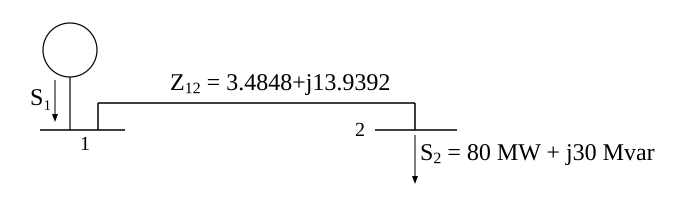

In [1]:
# TEST CELL
from myst_nb import glue
from IPython.display import SVG

svg = """
<svg xmlns="http://www.w3.org/2000/svg" width="700" height="220" viewBox="0 0 700 220">

  <!-- Bus 1 -->
  <line x1="40" y1="130" x2="125" y2="130" stroke="black" stroke-width="1.5"/>
  <text x="80" y="150" font-size="20">1</text>

  <!-- Generator -->
  <circle cx="70" cy="50" r="27" fill="none" stroke="black" stroke-width="1.2"/>
  <line x1="70" y1="77" x2="70" y2="130" stroke="black" stroke-width="1.2"/>

  <!-- S1 -->
  <text x="30" y="105" font-size="24">S₁</text>
  <line x1="55" y1="80" x2="55" y2="118" stroke="black" stroke-width="1"/>
  <polygon points="55,122 52,114 58,114" fill="black"/>

  <!-- Line -->
  <line x1="98" y1="103" x2="415" y2="103" stroke="black" stroke-width="1.5"/>
  <line x1="98" y1="103" x2="98" y2="130" stroke="black" stroke-width="1.5"/>
  <line x1="415" y1="103" x2="415" y2="130" stroke="black" stroke-width="1.5"/>

  <!-- Impedance label -->
  <text x="170" y="90" font-size="24">
    Z<tspan baseline-shift="sub" font-size="16">12</tspan>
    = 3.4848+j13.9392
  </text>

  <!-- Bus 2 -->
  <line x1="375" y1="130" x2="457" y2="130" stroke="black" stroke-width="1.5"/>
  <text x="355" y="136" font-size="20">2</text>

  <!-- S2 -->
  <text x="420" y="160" font-size="24">
    S<tspan baseline-shift="sub" font-size="16">2</tspan>
    = 80 MW + j30 Mvar
  </text>

  <line x1="415" y1="135" x2="415" y2="180" stroke="black" stroke-width="1"/>
  <polygon points="415,184 412,176 418,176" fill="black"/>

</svg>
"""

glue("last_flyt", SVG(svg), display=True)



## Oppgave 1: Y-buss

Bestem linjeadmittansen i per unit.

$$
y_{12}=\frac{1}{Z_{12}}
$$

og sett opp Y-bussmatrisen

$$
Y_{bus}=
\begin{bmatrix}
Y_{11} & Y_{12} \\
Y_{21} & Y_{22}
\end{bmatrix}.
$$

## Oppgave 2: Teoretisk beregning

Utfør fire iterasjoner (opptil $V_2^{(3)}$) av Gauss-Seidel-metoden for å estimere spenningen i buss 2.

Bruk startverdien

$$
V_2^{(0)} = 1+j0.
$$


## Oppgave 3: Effektflyt og linjetap

Etter flere Gauss-Seidel-iterasjoner har spenningen på buss 2 konvergert til

$$ V_2 = 0.955 - j0.058 \text{ p.u.} $$

Bestem:

1. Kompleks effekt fra buss 1 til buss 2,

$$
S_{12}.
$$

2. Kompleks effekt fra buss 2 til buss 1,

$$
S_{21}.
$$


Vis alle mellomregninger.

**Hint:**

$$
I_{12}
=
\frac{V_1-V_2}{Z_{12}}
$$

$$
I_{21}
=
-I_{12}
$$

$$
S_{12}
=
V_1 I_{12}^{*}
$$

$$
S_{21}
=
V_2 I_{21}^{*}
$$

Linjetapet bestemmes fra

$$
S_{L12}
=
S_{12}+S_{21}.
$$




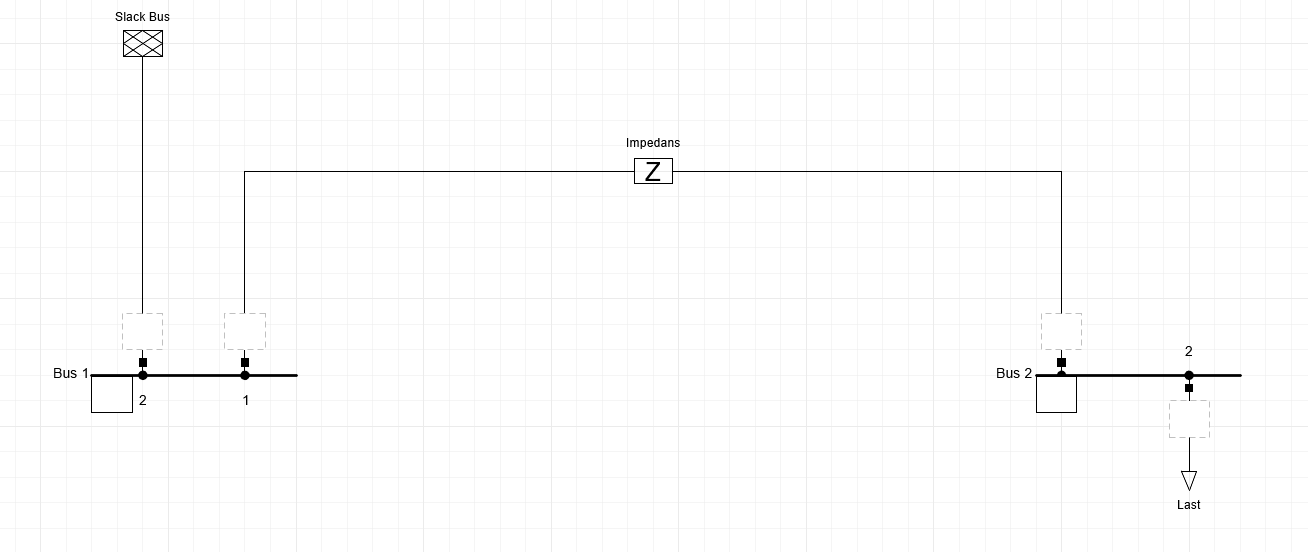

In [2]:
# TEST CELL
from IPython.display import Image

Image("../images/LAB5powerfactory.png", width=1000, height=800)

## Oppgave 4: Lastflyt i PowerFactory

Modeller systemet i DIgSILENT PowerFactory og utfør en lastflytberegning (Power Flow).

### Tips til modellering

Opprett følgende elementer i PowerFactory:

- **Busbar** (*ElmTerm*) for buss 1 (slack-buss)
- **Busbar** (*ElmTerm*) for buss 2 (PQ-buss)
- **External Grid** (*ElmXnet*) koblet til buss 1
- **Impedance** (*ElmZpu*) mellom buss 1 og buss 2
- **Load** (*ElmLod*) koblet til buss 2


### Gjennomføring

1. Opprett de to bussene.
2. Koble en **External Grid** til buss 1.
3. Legg inn lasten på buss 2.
4. Opprett linjen mellom bussene.
5. Angi linjens impedans.
6. Kjør **Load Flow**.

Registrer følgende resultater fra PowerFactory:

- Spenning ved buss 2
- Spenningsvinkel ved buss 2
- Aktiv effektflyt fra buss 1 til buss 2
- Reaktiv effektflyt fra buss 1 til buss 2

Bruk de rapporterte effektflytene til å beregne:

$$
P_{tap}
$$

og

$$
Q_{tap}
$$

for linjen.
### Sammenligning

Sammenlign resultatene med de manuelle Gauss-Seidel-beregningene.

Diskuter eventuelle forskjeller mellom resultatene.

## Oppgave 5: Sammenligning

Sammenlign resultatet fra den manuelle beregningen med resultatet fra programvaren.

Diskuter:

1. Hvorfor resultatene ikke nødvendigvis er identiske.
2. Betydningen av flere iterasjoner.
3. Hvorfor valg av startverdier kan påvirke konvergensen.

---

# Del 2: Utvidelse til 3-bussystem

## Systembeskrivelse

Systemet utvides med en tredje buss.

- Buss 1: Slack-buss
- Buss 2: Lastbuss (PQ)
- Buss 3: Lastbuss (PQ)

Linjeimpedanser:

## Systembeskrivelse

Systemet utvides med en tredje buss.

- Buss 1: Slack-buss
- Buss 2: Lastbuss (PQ-buss)
- Buss 3: Lastbuss (PQ-buss)

Linjeimpedanser:

$$
Z_{12}=3.4848+j13.9392\ \Omega
$$

$$
Z_{13}=1.7424+j8.7120\ \Omega
$$

$$
Z_{23}=2.6136+j10.4544\ \Omega
$$

Lastdata:

$$
S_2=80+j30\ \text{MVA}
$$

$$
S_3=50+j20\ \text{MVA}
$$

Nominell spenning:

$$
V_n=132\ \text{kV}
$$



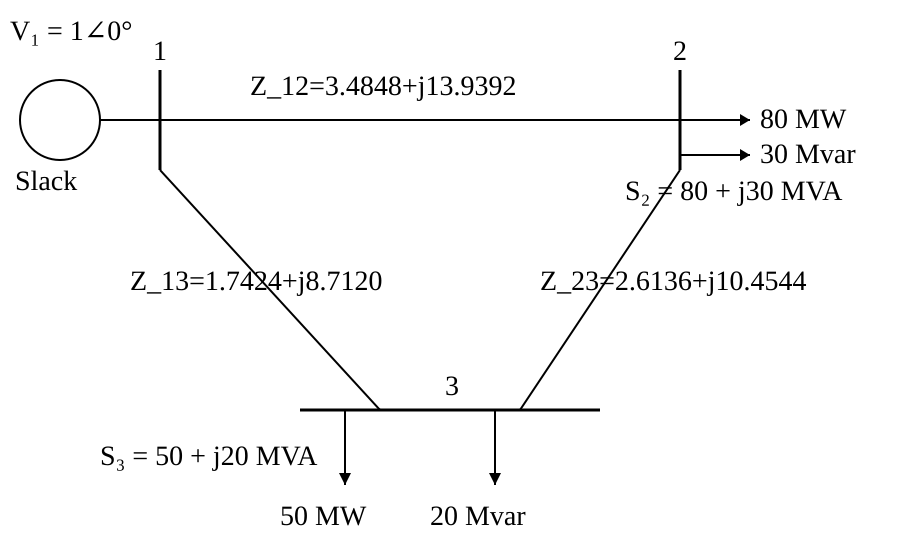

In [4]:
# TEST CELL
from myst_nb import glue
from IPython.display import SVG

svg = """
<svg xmlns="http://www.w3.org/2000/svg" width="900" height="550" viewBox="0 0 900 550">

  <style>
    .bus { stroke:black; stroke-width:3; }
    .line { stroke:black; stroke-width:2; fill:none; }
    .txt { font-family:"Times New Roman",serif; font-size:28px; }
    .small { font-family:"Times New Roman",serif; font-size:24px; }
  </style>

  <!-- Generator -->
  <circle cx="60" cy="120" r="40" fill="none" stroke="black" stroke-width="2"/>
  <line x1="100" y1="120" x2="160" y2="120" class="line"/>

  <text x="10" y="40" class="txt">V₁ = 1∠0°</text>
  <text x="15" y="190" class="txt">Slack</text>

  <!-- Bus 1 -->
  <line x1="160" y1="70" x2="160" y2="170" class="bus"/>
  <text x="153" y="60" class="txt">1</text>

  <!-- Bus 2 -->
  <line x1="680" y1="70" x2="680" y2="170" class="bus"/>
  <text x="673" y="60" class="txt">2</text>

  <!-- Top Line -->
  <line x1="160" y1="120" x2="680" y2="120" class="line"/>
  <text x="250" y="95" class="txt">Z_12=3.4848+j13.9392</text>

  <!-- Left branch -->
  <line x1="160" y1="170" x2="380" y2="410" class="line"/>
  <text x="130" y="290" class="txt">Z_13=1.7424+j8.7120</text>

  <!-- Right branch -->
  <line x1="680" y1="170" x2="520" y2="410" class="line"/>
  <text x="540" y="290" class="txt">Z_23=2.6136+j10.4544</text>

  <!-- Bus 3 -->
  <line x1="300" y1="410" x2="600" y2="410" class="bus"/>
  <text x="445" y="395" class="txt">3</text>

  

  <!-- Load at Bus 2 -->
  <line x1="680" y1="120" x2="750" y2="120" class="line"/>
  <polygon points="750,120 740,114 740,126" fill="black"/>
  <text x="760" y="128" class="txt">80 MW</text>

  <line x1="680" y1="155" x2="750" y2="155" class="line"/>
  <polygon points="750,155 740,149 740,161" fill="black"/>
  <text x="760" y="163" class="txt">30 Mvar</text>

  <!-- Bus 2 load label -->
  <text x="625" y="200" class="txt">S₂ = 80 + j30 MVA</text>

  <!-- Load at Bus 3 -->
  <line x1="345" y1="410" x2="345" y2="485" class="line"/>
  <polygon points="345,485 339,473 351,473" fill="black"/>
  <text x="280" y="525" class="txt">50 MW</text>

  <line x1="495" y1="410" x2="495" y2="485" class="line"/>
  <polygon points="495,485 489,473 501,473" fill="black"/>
  <text x="430" y="525" class="txt">20 Mvar</text>

  <!-- Bus 3 load label -->
  <text x="100" y="465" class="txt">S₃ = 50 + j20 MVA</text>

</svg>
"""

glue("last_flyt", SVG(svg), display=True)

## Oppgave 6: Y-buss for 3-bussystemet

Bestem linjeadmittansene per unit med samme baseverdier som i Del1.

$$
y_{12}=\frac{1}{Z_{12}},
\qquad
y_{13}=\frac{1}{Z_{13}},
\qquad
y_{23}=\frac{1}{Z_{23}}
$$

og konstruer Y-bussmatrisen

$$
Y_{bus}=
\begin{bmatrix}
Y_{11} & Y_{12} & Y_{13}\\
Y_{21} & Y_{22} & Y_{23}\\
Y_{31} & Y_{32} & Y_{33}
\end{bmatrix}.
$$

### Oppgave 7: Gauss-Seidel for 3-bussystemet

#### a)

Bruk Gauss-Seidel-metoden og startverdiene

$$
V_2^{(0)} = 1.0 + j0
$$

$$
V_3^{(0)} = 1.0 + j0
$$

Bestem spenningene ved buss 2 og buss 3.

Utfør **to iterasjoner** og vis alle mellomregninger.

Bestem:

$$
V_2^{(1)}, \; V_3^{(1)}
$$

og

$$
V_2^{(2)}, \; V_3^{(2)}.
$$

---

#### b)

Anta at busspenningene etter flere iterasjoner konvergerer til

$$
V_2 = 0.968 - j0.043 \ \text{p.u.}
$$

$$
V_3 = 0.977 - j0.032 \ \text{p.u.}
$$

(eventuellt noe justert for avrundinger)

Bestem:

1. Kompleks effekt levert fra slack-bussen,

$$
S_1=P_1+jQ_1.
$$

2. Kompleks effekt ved buss 2,

$$
S_2=P_2+jQ_2.
$$

3. Kompleks effekt ved buss 3,

$$
S_3=P_3+jQ_3.
$$




## Oppgave 8: Lastflytberegning

Utvid Power Factory modellen til 3-buss.

Bestem:

- Spenning ved alle busser
- Spenningsvinkel ved alle busser
- Aktiv effektflyt i alle linjer
- Reaktiv effektflyt i alle linjer

Presenter resultatene i en oversiktlig tabell.



## Oppgave 9: Refleksjon

Besvar følgende spørsmål:

1. Hvilken buss får størst spenningsfall?
2. Hvilken linje blir mest belastet?
3. Hvordan påvirker økt last spenningsnivåene i nettet?
4. Hvorfor er en slack-buss nødvendig i en lastflytberegning?
5. Hvilke begrensninger har denne modellen sammenlignet med et reelt distribusjonsnett på Vestlandet?

---

# Innlevering

Lever følgende:

1. Beregninger og utledninger.
2. Oppsatt Y-bussmatrise.
3. Enlinjeskjema.
4. Resultattabeller fra simuleringene.
5. Svar på refleksjonsspørsmålene.

---

